# Neural models on GoEmotions sentiment — Dense, RNN and LSTM

**IT2-18** · Binary sentiment classification (0 = negative, 1 = positive) on the balanced 800 / 200 train / test split.

**Objective.** Train the neural models of the task and compare them with the chance-level baseline of `02_baseline_model.ipynb`. This notebook is shared by the team: each member fills only their own section.

| Section | Owner | Model | Status |
|---|---|---|---|
| Dense | Restrepo | TF-IDF + `MLPClassifier` in one `Pipeline` | this commit |
| RNN | Varela | Keras `SimpleRNN` | empty, later commit |
| LSTM | Granda | Keras `LSTM` | empty, later commit |
| Comparison | Granda | all models, train-test gap, confidence intervals | empty, later commit |

**Outputs of the Dense section**
- `outputs/metrics/dense_metrics.csv` — accuracy, precision, recall, F1, macro F1 and Cohen's kappa on train and test.
- `outputs/figures/dense_confusion_matrix.png` and `outputs/figures/dense_top_terms.png`.
- `outputs/saved_models/dense_pipeline.joblib` — the fitted pipeline (TF-IDF + MLP).
- The tuning step also rewrites `outputs/metrics/dense_grid_results.csv`, `outputs/metrics/dense_best_params.json` and `logs/training_logs_dense.txt`.

**Step order (the professor's workflow, slide 18):** importing the libraries → loading the dataset → splitting the dataset → building the model → hyperparameter fine tuning → best configuration → training the model → prediction on the training set → prediction on the test set → metrics on both splits → confusion matrix → interpretation.

**Rules we follow.** Seed `1234` everywhere. The vectorizer lives inside the pipeline, so each fit or CV fold learns its vocabulary from training rows only (no leakage). Tuning uses cross-validation on the train split only, scored with Cohen's kappa. The test set is used once, after the model is fixed.

## Shared setup — which libraries and data does every model need?

Imports are grouped by library. The same train and test files are used by every model, so all results are comparable.

In [17]:
import json
import os
import random
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp

root = Path.cwd().resolve()
if not (root / "src" / "evaluate.py").exists():
    root = root.parent
if not (root / "src" / "evaluate.py").exists():
    raise FileNotFoundError("Run this notebook from the project root or notebooks/ directory")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
os.chdir(root)  # src.train writes logs/ and outputs/ relative to the project root

from src.evaluate import evaluate_train_test, save_metrics
from src.models import build_dense_pipeline
from src.train import DENSE_PARAM_GRID, run_dense_grid
from src.visualize import plot_confusion_matrix

SEED = 1234
random.seed(SEED)
np.random.seed(SEED)
# The Keras sections (RNN, LSTM) must also call src.train.set_seed(SEED) before building a model.

### Loading the dataset

Both files were created in IT2-07 with a stratified, seeded split. `clean_text` is the cleaned comment used by the models.

In [18]:
train = pd.read_csv(root / "data" / "processed" / "train.csv")
test = pd.read_csv(root / "data" / "processed" / "test.csv")

required_columns = {"comment_id", "text", "clean_text", "label"}
assert required_columns.issubset(train.columns)
assert required_columns.issubset(test.columns)
assert len(train) == 800 and len(test) == 200
assert train["label"].value_counts().to_dict() == {0: 400, 1: 400}
assert test["label"].value_counts().to_dict() == {0: 100, 1: 100}

print("Train:", train.shape, "Test:", test.shape)
print("Train labels:", train["label"].value_counts().sort_index().to_dict())
print("Test labels:", test["label"].value_counts().sort_index().to_dict())
print("Empty clean_text -> train:", int(train["clean_text"].isna().sum()), "| test:", int(test["clean_text"].isna().sum()))
display(train[["clean_text", "label"]].head(3))

Train: (800, 4) Test: (200, 4)
Train labels: {0: 400, 1: 400}
Test labels: {0: 100, 1: 100}
Empty clean_text -> train: 0 | test: 0


,clean_text,label
0,sure men career supermodel fighting appreciate...,1
1,players older retiring looks like might never ...,0
2,fact think like terrifying,0


**Insight:** both splits are perfectly balanced (400 / 400 in train, 100 / 100 in test), so a model that guesses has accuracy near 0.50 and kappa near 0. There are no empty cleaned texts, so every comment gives the vectorizer at least one word.

## Dense

### What is a dense network on TF-IDF features?

TF-IDF turns each comment into one fixed-size vector that counts words (and word pairs) weighted by how rare they are. A dense network (`MLPClassifier`) reads that vector and outputs the probability of the positive class. The vector has **no word order and no memory**: the model is a fixed function of the words present, so "not good" can only be recognised if the pair `not good` was kept as a feature.

### Splitting the dataset — which rows are used for tuning?

The split already exists. The model sees `clean_text` and `label` of the train rows only while it is tuned and fitted. A comment made only of stopwords would have an empty `clean_text`, which pandas reads as a missing value. There are none in these splits, but `fillna("")` keeps the code safe.

In [19]:
X_train = train["clean_text"].fillna("")
y_train = train["label"].to_numpy()
X_test = test["clean_text"].fillna("")
y_test = test["label"].to_numpy()
print("X_train:", X_train.shape, "| X_test:", X_test.shape)

X_train: (800,) | X_test: (200,)


### Building the model — what does the pipeline contain?

`build_dense_pipeline` (IT2-16) chains `TfidfVectorizer` and `MLPClassifier`. Because both steps are inside one `Pipeline`, every cross-validation fold fits its own vocabulary on its own training rows.

In [4]:
pipeline = build_dense_pipeline()
for step_name, step in pipeline.steps:
    print(step_name, "->", step)

tfidf -> TfidfVectorizer(min_df=2, ngram_range=(1, 2), sublinear_tf=True)
mlp -> MLPClassifier(alpha=0.001, early_stopping=True, hidden_layer_sizes=(64,),
              max_iter=300, random_state=1234)


**Insight:** the starting point uses unigrams and bigrams (`ngram_range=(1, 2)`), drops terms that appear in fewer than 2 comments (`min_df=2`), scales term counts with a logarithm (`sublinear_tf`) and has one hidden layer of 64 ReLU units. Early stopping uses a validation slice taken inside the training rows, and `random_state=1234` makes the run repeatable. These are defaults to be tuned, not final choices.

### What about the hyperparameter fine tuning?

`run_dense_grid` (IT2-17) runs `GridSearchCV` on the **train split only**: 4 hidden-layer sizes × 2 activations × 3 `alpha` × 2 learning rates = 48 candidates, 5 stratified folds each. The score is Cohen's kappa through `make_scorer(cohen_kappa_score)`. The slide passes the bare metric function, which is not a valid scorer.

In [5]:
grid = run_dense_grid(X_train, y_train, DENSE_PARAM_GRID, cv=5, n_jobs=-1)

cv_results = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score")
top = cv_results[
    ["param_mlp__hidden_layer_sizes", "param_mlp__activation", "param_mlp__alpha",
     "param_mlp__learning_rate_init", "mean_test_score", "std_test_score", "mean_train_score"]
].head(10)
top.columns = ["hidden", "activation", "alpha", "lr_init", "val_kappa", "val_kappa_std", "train_kappa"]
print("Candidates:", len(cv_results), "| folds: 5 | rows used:", len(X_train))
display(top.round(4).reset_index(drop=True))

Candidates: 48 | folds: 5 | rows used: 800


,hidden,activation,alpha,lr_init,val_kappa,val_kappa_std,train_kappa
0,"(64,)",relu,0.01,0.01,0.4700,0.0400,0.8344
1,"(64, 32)",relu,0.01,0.01,0.4675,0.0451,0.9000
2,"(128,)",relu,0.0001,0.001,0.4625,0.0316,0.8638
3,"(128,)",relu,0.001,0.001,0.4625,0.0316,0.8612
4,"(32,)",relu,0.01,0.01,0.4600,0.0752,0.8538
5,"(64,)",relu,0.001,0.01,0.4575,0.0510,0.8144
6,"(64,)",relu,0.0001,0.01,0.4550,0.0472,0.8219
7,"(128,)",relu,0.01,0.001,0.4550,0.0451,0.8587
8,"(64, 32)",relu,0.0001,0.01,0.4550,0.0625,0.8812
9,"(32,)",tanh,0.01,0.01,0.4500,0.0622,0.8575


**Insight:** the best candidates are very close: the top ten differ by about 0.02 in mean validation kappa, while the fold-to-fold standard deviation is 0.03 to 0.08. Nine of the ten best use `relu`. The train kappa of these candidates (0.81 to 0.90) is far above the validation kappa (about 0.46), so the network memorises the 640 rows it sees in each fold. This is the main weakness of a bag-of-words model with so little data.

### How do we get the best model's configuration?

In [6]:
best_params = grid.best_params_
best_cv_kappa = grid.best_score_
best_std = cv_results["std_test_score"].iloc[0]
near_best = int((cv_results["mean_test_score"] >= best_cv_kappa - best_std).sum())

print("Best parameters:", best_params)
print(f"Best mean CV kappa: {best_cv_kappa:.4f} (std {best_std:.4f})")
print(f"Candidates within one std of the best: {near_best} of {len(cv_results)}")

Best parameters: {'mlp__activation': 'relu', 'mlp__alpha': 0.01, 'mlp__hidden_layer_sizes': (64,), 'mlp__learning_rate_init': 0.01}
Best mean CV kappa: 0.4700 (std 0.0400)
Candidates within one std of the best: 22 of 48


**Insight:** `GridSearchCV` returns `relu`, `alpha=0.01`, one hidden layer of 64 units and learning rate 0.01, with a mean CV kappa of 0.47. As in the professor's workflow we keep `best_params_`. But 22 of the 48 candidates are within one standard deviation of it, so the data cannot tell the best configuration apart from many neighbours. We report it as a good configuration, not as a clear winner.

### Training the model

We rebuild the pipeline with the best parameters and fit it on the whole train split. `GridSearchCV` already refitted its `best_estimator_` the same way, so we check that both give the same predictions.

In [7]:
dense = build_dense_pipeline(**best_params)
dense.fit(X_train, y_train)

assert (dense.predict(X_train) == grid.best_estimator_.predict(X_train)).all()
print("TF-IDF vocabulary size:", len(dense.named_steps["tfidf"].vocabulary_))
print("MLP iterations until early stopping:", dense.named_steps["mlp"].n_iter_)

TF-IDF vocabulary size: 786
MLP iterations until early stopping: 19


### Prediction on training set

In [8]:
pred_train = dense.predict(X_train)
print("Predicted positives:", int(pred_train.sum()), "of", len(pred_train))

Predicted positives: 391 of 800


### Prediction on test set

The test set is used here for the first and only time. The model, the vocabulary and the hyperparameters are already fixed.

In [9]:
pred_test = dense.predict(X_test)
print("Predicted positives:", int(pred_test.sum()), "of", len(pred_test))

Predicted positives: 98 of 200


### Train and test metrics — does the model generalise?

Same metrics on both splits, computed with the project helper. Precision, recall and F1 are for the positive class (`average='binary'`); macro F1 is reported too.

In [10]:
dense_metrics = evaluate_train_test("dense", y_train, pred_train, y_test, pred_test)
metrics_path = save_metrics(dense_metrics, "dense")
saved = pd.read_csv(metrics_path)
assert len(saved) == 2 and set(saved["split"]) == {"train", "test"}
display(saved.round(4))

baseline = pd.read_csv(root / "outputs" / "metrics" / "baseline_metrics.csv")
baseline_test = baseline[baseline["split"] == "test"]
best_baseline_acc = baseline_test["accuracy"].max()
dense_test = saved[saved["split"] == "test"].iloc[0]
dense_train = saved[saved["split"] == "train"].iloc[0]
assert dense_test["accuracy"] > best_baseline_acc, "Dense network must beat the baseline"
print(f"Best baseline test accuracy: {best_baseline_acc:.3f} | dense test accuracy: {dense_test['accuracy']:.3f}")
print(f"Train-test gap -> accuracy: {dense_train['accuracy'] - dense_test['accuracy']:.3f} | kappa: {dense_train['kappa'] - dense_test['kappa']:.3f}")

,model,split,accuracy,precision,recall,f1,f1_macro,kappa
0,dense,train,0.9588,0.9693,0.9475,0.9583,0.9587,0.9175
1,dense,test,0.7200,0.7245,0.7100,0.7172,0.7200,0.4400


Best baseline test accuracy: 0.515 | dense test accuracy: 0.720
Train-test gap -> accuracy: 0.239 | kappa: 0.478


**Insight:** on the test set the dense network reaches accuracy 0.72 and kappa 0.44, much better than the best baseline (accuracy 0.515, kappa near 0), so it learns real sentiment signal from the words. On the training set it reaches accuracy 0.96 and kappa 0.92, a gap of 0.24 in accuracy and 0.48 in kappa: the model overfits. The cross-validation kappa (0.47) is close to the test kappa (0.44), which suggests the tuning did not leak information and the CV estimate was honest. Precision (0.72) and recall (0.71) are balanced.

### How reliable is a score on 200 comments?

With only 200 test rows, one comment is 0.5 percentage points. A rough 95% interval for the accuracy (normal approximation of a proportion) shows how much of a difference between models could be noise. The bootstrap intervals for the final comparison come in the Comparison section.

In [11]:
n_test = len(y_test)
acc = float(dense_test["accuracy"])
half_width = 1.96 * np.sqrt(acc * (1 - acc) / n_test)
print(f"Test accuracy {acc:.3f}, rough 95% interval: [{acc - half_width:.3f}, {acc + half_width:.3f}] (+/- {half_width:.3f})")
print(f"Comments wrongly classified: {int((pred_test != y_test).sum())} of {n_test}")

Test accuracy 0.720, rough 95% interval: [0.658, 0.782] (+/- 0.062)
Comments wrongly classified: 56 of 200


**Insight:** the rough 95% interval for the test accuracy is about 0.66 to 0.78. With 200 comments, differences of a few points between two models are inside the noise, so we will not call a model better only because of one or two points. The Comparison section uses bootstrap intervals for this.

### Confusion matrix on the test set

Rows are the true labels and columns the predictions, ordered negative (0) and positive (1).

In [12]:
fig = plot_confusion_matrix(y_test, pred_test, labels=[0, 1], name="dense_confusion_matrix")
plt.show()

from src.evaluate import confusion_matrix_data
cm = confusion_matrix_data(y_test, pred_test)
print(cm)
assert (root / "outputs" / "figures" / "dense_confusion_matrix.png").is_file()

<Figure size 600x500 with 2 Axes>

{'tn': 73, 'fp': 27, 'fn': 29, 'tp': 71}


**Insight:** the model makes 27 false positives and 29 false negatives, almost the same number, so it does not lean towards one class. It gets 73 of 100 negative and 71 of 100 positive comments right. The errors are probably comments whose sentiment depends on word order, negation or sarcasm, which a bag of words cannot represent; the final error analysis will check this.

### Which words push the prediction towards positive or negative?

An `MLPClassifier` has no single weight per word, because the hidden layer mixes them. To still read the model, we probe it: each vocabulary term alone becomes one TF-IDF vector (a unit vector, since rows are L2-normalised) and we read the **log-odds** of the positive class. The probabilities of single words saturate near 0 or 1, so log-odds keep the ranking readable. This is a one-word probe, not a linear coefficient: it ignores interactions between words, so it is a guide, not an exact explanation.

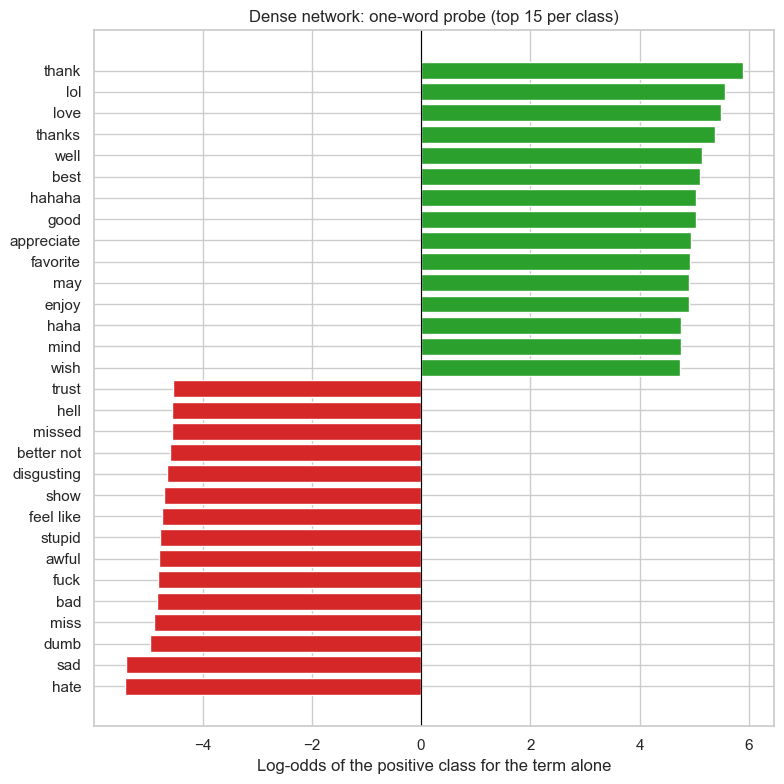

Top positive: thank, lol, love, thanks, well, best, hahaha, good, appreciate, favorite
Top negative: hate, sad, dumb, miss, bad, fuck, awful, stupid, feel like, show
Terms with log-odds > 0: 378 of 786


In [13]:
tfidf = dense.named_steps["tfidf"]
mlp = dense.named_steps["mlp"]
terms = tfidf.get_feature_names_out()
positive_column = list(mlp.classes_).index(1)

probe = sp.identity(len(terms), format="csr")  # row i = term i alone
p_positive = np.clip(mlp.predict_proba(probe)[:, positive_column], 1e-9, 1 - 1e-9)
log_odds = pd.Series(np.log(p_positive / (1 - p_positive)), index=terms).sort_values()

top_negative = log_odds.head(15)
top_positive = log_odds.tail(15)
shown = pd.concat([top_negative, top_positive])

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(shown.index, shown.values, color=["tab:red"] * 15 + ["tab:green"] * 15)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(title="Dense network: one-word probe (top 15 per class)", xlabel="Log-odds of the positive class for the term alone")
fig.tight_layout()
figure_path = root / "outputs" / "figures" / "dense_top_terms.png"
figure_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_path, dpi=150, bbox_inches="tight")
plt.show()
assert figure_path.is_file() and figure_path.stat().st_size > 0

print("Top positive:", ", ".join(top_positive.index[::-1][:10]))
print("Top negative:", ", ".join(top_negative.index[:10]))
print("Terms with log-odds > 0:", int((log_odds > 0).sum()), "of", len(log_odds))

**Insight:** the words with the strongest positive push are `thank`, `lol`, `love`, `thanks`, `best`, `good`, `appreciate`, and the strongest negative are `hate`, `sad`, `dumb`, `miss`, `bad`, `awful`, `stupid`. These agree with common sense, so the network learned sensible vocabulary. The bigrams `better not` and `feel like` also appear on the negative side, which shows that keeping bigrams gives the model a little local context (and that we kept negations in the cleaning). Some terms (`trust`, `show`, `may`, `mind`, `wish`) are less obviously emotional and probably reflect the small training sample. 378 of 786 terms lean positive, so the vocabulary is balanced.

### Saving the fitted pipeline

The pipeline is small (a vocabulary of a few hundred terms and one hidden layer), so it can be stored in the repository. Loading it needs the same library versions (`environment.yml`).

In [14]:
model_path = root / "outputs" / "saved_models" / "dense_pipeline.joblib"
model_path.parent.mkdir(parents=True, exist_ok=True)
joblib.dump(dense, model_path)

size_kb = model_path.stat().st_size / 1024
assert size_kb < 5000, "Model file is too big to commit"
reloaded = joblib.load(model_path)
assert (reloaded.predict(X_test) == pred_test).all()
print(f"Saved {model_path.name}: {size_kb:.0f} KB; the reloaded pipeline gives the same test predictions.")

Saved dense_pipeline.joblib: 1284 KB; the reloaded pipeline gives the same test predictions.


### Takeaways of the Dense section

- **Result:** TF-IDF + dense network reaches test accuracy 0.72 and kappa 0.44, clearly above the chance-level baseline (accuracy about 0.5, kappa near 0).
- **Overfitting:** train accuracy 0.96 against test accuracy 0.72. With 800 training rows and 786 features, the network memorises; the best candidate has the strongest `alpha` of the grid (0.01), but even so the gap stays large, and the differences between `alpha` values are within the noise.
- **Tuning:** many configurations are statistically tied (22 of 48 within one standard deviation), so the chosen configuration should not be presented as a sharp winner.
- **No order, no memory:** the input is a bag of words, so the model is a fixed function of which words appear. It can use a bigram such as `better not`, but it cannot follow longer context. This is the reference that the RNN and the LSTM have to improve.
- **Test set size:** 200 comments give a 95% interval of about +/- 0.06 for the accuracy; comparisons with the RNN and the LSTM must take this into account.

## RNN

### What is a vanilla RNN?

A recurrent neural network (RNN) reads a comment as a sequence of tokens. At each time step, the `SimpleRNN` cell combines the current word embedding with a hidden state that carries information from earlier words. This gives it access to word order and short context, unlike the Dense model on TF-IDF features.

The hidden state is updated repeatedly as the sequence is read. In a vanilla RNN, gradients can become very small when they are propagated through many time steps (the **vanishing-gradient problem**). This makes it difficult to learn dependencies between words that are far apart. An LSTM uses gates to address this limitation; that model is covered in the next section.

### Preparing the sequences — how do we prevent data leakage?

We keep the same 800/200 split loaded above. The vocabulary is adapted using **only `X_train`**. The test comments are transformed with the already-fitted vectorizer and are not used for vocabulary creation or hyperparameter selection. `max_words` and `max_len` come from the EDA summary created earlier.

In [24]:
from src.preprocessing import build_vectorizer
from src.models import build_rnn
from src.train import KERAS_PARAM_GRID, set_seed, run_keras_grid, fit_best_keras
from src.visualize import plot_learning_curves

with open(root / "outputs" / "metrics" / "eda_summary.json", encoding="utf-8") as file:
    eda_summary = json.load(file)

max_words = int(eda_summary["max_words"])
max_len = int(eda_summary["max_len"])

set_seed(SEED)

vectorizer = build_vectorizer(
    X_train,
    max_tokens=max_words,
    max_len=max_len,
)

X_train_seq = np.asarray(vectorizer(X_train.tolist()))
X_test_seq = np.asarray(vectorizer(X_test.tolist()))

assert X_train_seq.shape == (len(X_train), max_len)
assert X_test_seq.shape == (len(X_test), max_len)
assert int(X_train_seq.max()) < max_words
assert int(X_test_seq.max()) < max_words

print("Vocabulary limit:", max_words)
print("Sequence length:", max_len)
print("Train sequences:", X_train_seq.shape)
print("Test sequences:", X_test_seq.shape)
print("The vectorizer was adapted on training comments only.")

Vocabulary limit: 2302
Sequence length: 13
Train sequences: (800, 13)
Test sequences: (200, 13)
The vectorizer was adapted on training comments only.


**Insight:** each comment is represented by a fixed-length sequence of integer token IDs. Short comments are padded and longer comments are truncated to `max_len`. This keeps the input shape consistent. The test set is only transformed here; it is not inspected to choose the vocabulary or sequence length.

### Hyperparameter tuning — which RNN configuration works best?

We use the manual Keras grid from IT2-20. It evaluates all combinations in `KERAS_PARAM_GRID` using a validation split taken from the training data. Early stopping monitors validation loss and restores the best weights. Configurations are ranked by validation Cohen's kappa; if two configurations have the same kappa, the one with lower validation loss is preferred.

The grid includes the number of recurrent units, embedding dimension, dropout, batch size and optimizer/learning rate. The test split is not passed to the tuning function.

In [25]:
set_seed(SEED)

rnn_grid_results = run_keras_grid(
    build_rnn,
    KERAS_PARAM_GRID,
    X_train_seq,
    y_train,
    model_name="rnn",
    model_kwargs={"max_words": max_words, "max_len": max_len},
    epochs=30,
    verbose=0,
)

rnn_grid_results = rnn_grid_results.sort_values(
    ["val_kappa", "val_loss"],
    ascending=[False, True],
).reset_index(drop=True)

rnn_grid_path = root / "outputs" / "metrics" / "rnn_grid_results.csv"
rnn_grid_path.parent.mkdir(parents=True, exist_ok=True)
rnn_grid_results.to_csv(rnn_grid_path, index=False)

print("Configurations evaluated:", len(rnn_grid_results))
display(rnn_grid_results.round(4))


Configurations evaluated: 72


,units,embedding_dim,dropout,batch_size,optimizer,val_loss,val_accuracy,val_precision,val_recall,val_f1,val_kappa,training_seconds,trainable_parameters,epochs_trained
0,64,100,0.2,64,Adam,0.6554,0.7000,0.7000,0.7000,0.7000,0.4000,5.2455,242873,4
1,64,100,0.5,64,RMSprop,0.6221,0.6812,0.6465,0.8000,0.7151,0.3625,4.5338,242873,4
2,32,50,0.2,16,RMSprop,0.6587,0.6812,0.6835,0.6750,0.6792,0.3625,4.2041,118845,3
3,128,50,0.5,32,RMSprop,0.6240,0.6750,0.7500,0.5250,0.6176,0.3500,118.8643,142173,3
4,64,100,0.5,16,RMSprop,0.6270,0.6688,0.7143,0.5625,0.6294,0.3375,4.9422,242873,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,32,50,0.5,32,RMSprop,0.6920,0.5125,0.5278,0.2375,0.3276,0.0250,3.0904,118845,2
68,128,50,0.2,32,Adam,0.6892,0.5062,0.5035,0.8875,0.6425,0.0125,4.8681,142173,2
69,128,50,0.5,32,Adam,0.6923,0.5000,0.5000,0.8875,0.6396,0.0000,5.1494,142173,2
70,128,100,0.2,32,Adam,0.6901,0.4875,0.4921,0.7750,0.6019,-0.0250,8.2387,263673,2


### Selecting and refitting the best configuration

The first row after sorting is the selected configuration. We then build a fresh RNN and fit it on the training split, keeping an internal validation slice for early stopping. The test set remains untouched until the model and training procedure are fixed.

In [26]:
best_rnn_row = rnn_grid_results.iloc[0]
rnn_param_names = ["units", "embedding_dim", "dropout", "batch_size", "optimizer", "lr"]
best_rnn_params = {
    key: best_rnn_row[key].item() if hasattr(best_rnn_row[key], "item") else best_rnn_row[key]
    for key in rnn_param_names
    if key in rnn_grid_results.columns
}

print("Best RNN configuration:")
for key, value in best_rnn_params.items():
    print(f"  {key}: {value}")
print(f"Validation kappa: {best_rnn_row['val_kappa']:.4f}")
print(f"Validation loss: {best_rnn_row['val_loss']:.4f}")

set_seed(SEED)
rnn, rnn_history = fit_best_keras(
    build_rnn,
    best_rnn_params,
    X_train_seq,
    y_train,
    model_name="rnn",
    model_kwargs={"max_words": max_words, "max_len": max_len},
    epochs=30,
    verbose=0,
)

rnn_parameter_count = int(rnn.count_params())
print(f"Trainable parameters: {rnn.count_params():,}")

Best RNN configuration:
  units: 64
  embedding_dim: 100
  dropout: 0.2
  batch_size: 64
  optimizer: Adam
Validation kappa: 0.4000
Validation loss: 0.6554
Trainable parameters: 242,873


### Learning curves — how did training progress?

The learning curves show training and validation loss and accuracy across epochs. A widening gap between training and validation curves can indicate overfitting. Early stopping limits unnecessary epochs and restores the weights from the best validation-loss epoch.

In [27]:
learning_curve_fig = plot_learning_curves(rnn_history, name="rnn_learning_curves")
plt.show()
learning_curve_path = root / "outputs" / "figures" / "rnn_learning_curves.png"
assert learning_curve_path.is_file() and learning_curve_path.stat().st_size > 0

history_frame = pd.DataFrame(rnn_history.history)
display(history_frame.tail().round(4))

<Figure size 1200x400 with 2 Axes>

,loss,accuracy,val_loss,val_accuracy
0,0.6973,0.4922,0.6890,0.5188
1,0.6284,0.8078,0.6583,0.6313
2,0.3985,0.9094,0.6554,0.7000
3,0.1136,0.9781,0.7955,0.7125


### Predictions — when do we use the test set?

The model is now fixed. We first calculate predictions on the training rows to measure fit. Then we make **one prediction pass** over the test rows. Those same saved test predictions are reused for the metrics and confusion matrix below; the test set is not used again for model selection or fitting.

In [28]:
rnn_pred_train = (rnn.predict(X_train_seq, verbose=0).ravel() >= 0.5).astype(int)
print("Training predictions:", len(rnn_pred_train), "| predicted positives:", int(rnn_pred_train.sum()))

Training predictions: 800 | predicted positives: 383


In [29]:
rnn_test_probabilities = rnn.predict(X_test_seq, verbose=0).ravel()
rnn_pred_test = (rnn_test_probabilities >= 0.5).astype(int)
print("Test predictions:", len(rnn_pred_test), "| predicted positives:", int(rnn_pred_test.sum()))
assert len(rnn_pred_test) == len(y_test)

Test predictions: 200 | predicted positives: 93


### Train and test metrics — does the RNN generalise?

We use the project's shared evaluation helper so the RNN reports the same metrics as the Dense model: accuracy, precision, recall, F1, macro F1 and Cohen's kappa. Both sets of predictions are already fixed; calculating these metrics does not require another model prediction.

In [30]:
rnn_metrics = evaluate_train_test(
    "rnn",
    y_train,
    rnn_pred_train,
    y_test,
    rnn_pred_test,
)
rnn_metrics_path = save_metrics(rnn_metrics, "rnn")
rnn_metrics_saved = pd.read_csv(rnn_metrics_path)

assert len(rnn_metrics_saved) == 2
assert set(rnn_metrics_saved["split"]) == {"train", "test"}
display(rnn_metrics_saved.round(4))

rnn_train_row = rnn_metrics_saved[rnn_metrics_saved["split"] == "train"].iloc[0]
rnn_test_row = rnn_metrics_saved[rnn_metrics_saved["split"] == "test"].iloc[0]
print(
    "Train-test gap -> "
    f"accuracy: {rnn_train_row['accuracy'] - rnn_test_row['accuracy']:.3f} | "
    f"kappa: {rnn_train_row['kappa'] - rnn_test_row['kappa']:.3f}"
)

,model,split,accuracy,precision,recall,f1,f1_macro,kappa
0,rnn,train,0.9062,0.9243,0.885,0.9042,0.9062,0.8125
1,rnn,test,0.7050,0.7204,0.670,0.6943,0.7046,0.4100


Train-test gap -> accuracy: 0.201 | kappa: 0.403


### Confusion matrix — which classes are misclassified?

The confusion matrix uses the same single set of test predictions created above. Rows are the true labels and columns are predicted labels, ordered negative (0) and positive (1).

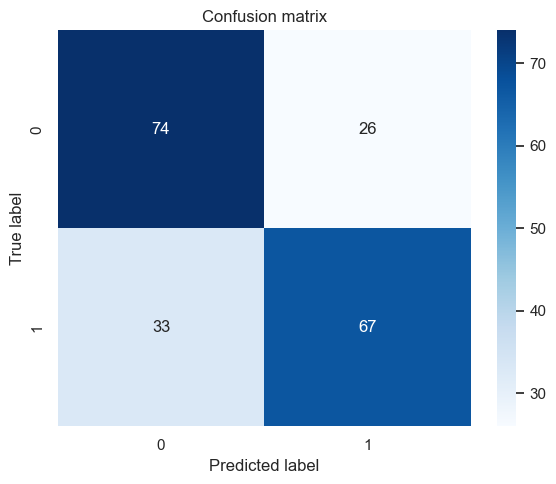

{'tn': 74, 'fp': 26, 'fn': 33, 'tp': 67}


In [31]:
rnn_cm_fig = plot_confusion_matrix(
    y_test,
    rnn_pred_test,
    labels=[0, 1],
    name="rnn_confusion_matrix",
)
plt.show()

from src.evaluate import confusion_matrix_data
rnn_cm = confusion_matrix_data(y_test, rnn_pred_test)
print(rnn_cm)

rnn_confusion_path = root / "outputs" / "figures" / "rnn_confusion_matrix.png"
assert rnn_confusion_path.is_file() and rnn_confusion_path.stat().st_size > 0

### Saving the fitted RNN

The selected model is saved only if the resulting file is small enough to keep in the repository. The saved model can be loaded later for inference without repeating the grid search.

In [32]:
rnn_model_path = root / "outputs" / "saved_models" / "rnn_best.keras"
rnn_model_path.parent.mkdir(parents=True, exist_ok=True)
rnn.save(rnn_model_path)

rnn_model_size_mb = rnn_model_path.stat().st_size / (1024 ** 2)
print(f"Saved model size: {rnn_model_size_mb:.2f} MB")
assert rnn_model_size_mb < 5, "RNN model exceeds the repository's 5 MB guideline"

rnn_reloaded = __import__("tensorflow").keras.models.load_model(rnn_model_path)
print("Reloaded model output shape:", rnn_reloaded(X_test_seq[:4]).shape)

Saved model size: 2.81 MB
Reloaded model output shape: (4, 1)


### Takeaways of the RNN section

- **Sequence information:** unlike TF-IDF, the RNN processes tokens in order and carries a hidden state from one time step to the next. This allows it to use local word order and context.
- **Vanishing gradients:** a vanilla `SimpleRNN` repeatedly propagates information through its hidden state. During backpropagation through many time steps, gradients can shrink, making long-range dependencies difficult to learn. LSTM gates are designed to help preserve information over longer sequences.
- **Long comments:** all comments are represented with the same `max_len` taken from the training EDA summary. Comments longer than this limit are truncated, so information near the end can be lost. This is a modelling trade-off rather than evidence that all comments are short.
- **Generalisation:** compare the train and test rows in `rnn_metrics.csv`. A large train–test gap is evidence of overfitting; validation kappa is the tuning criterion, while the test metrics are the final held-out estimate.
- **Comparison:** the next sections will place the RNN beside the Dense model and LSTM using the same train/test split and evaluation metrics.

## LSTM

## Comparison